In [7]:
import pandas as pd

df = pd.read_csv("/content/Admission_Predict.csv")


df.columns = df.columns.str.strip()
columns = df.columns
print(columns.tolist())


['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']


In [8]:
df.drop("Serial No.", axis=1, inplace=True)

y = df['Chance of Admit']
df.drop("Chance of Admit", axis=1, inplace=True)

df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,337,118,4,4.5,4.5,9.65,1
1,324,107,4,4.0,4.5,8.87,1
2,316,104,3,3.0,3.5,8.00,1
3,322,110,3,3.5,2.5,8.67,1
4,314,103,2,2.0,3.0,8.21,0


In [9]:
print("Features shape:", df.shape)
print("Target shape:  ", y.shape)
df.info()

Features shape: (500, 7)
Target shape:   (500,)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          500 non-null    int64  
 1   TOEFL Score        500 non-null    int64  
 2   University Rating  500 non-null    int64  
 3   SOP                500 non-null    float64
 4   LOR                500 non-null    float64
 5   CGPA               500 non-null    float64
 6   Research           500 non-null    int64  
dtypes: float64(3), int64(4)
memory usage: 27.5 KB


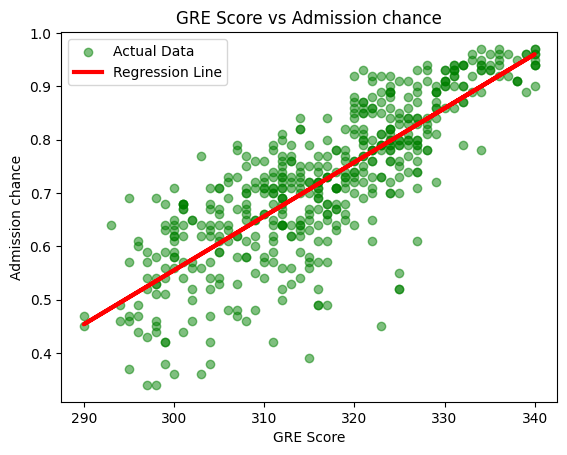

In [10]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


simple_lr = LinearRegression()
simple_lr.fit(df[['GRE Score']], y)

plt.scatter(df['GRE Score'], y, color='green', label='Actual Data', alpha=0.5)
plt.plot(df['GRE Score'], simple_lr.predict(df[['GRE Score']]), color='red', linewidth=3, label='Regression Line')
plt.xlabel('GRE Score')
plt.ylabel('Admission chance')
plt.title('GRE Score vs Admission chance')
plt.legend()
plt.show()

In [11]:
print("Slope (coefficient):", simple_lr.coef_[0])
print("Intercept:           ", simple_lr.intercept_)
print("R² score:            ", simple_lr.score(df[['GRE Score']], y))

Slope (coefficient): 0.010125871060764588
Intercept:            -2.4828146663422905
R² score:             0.656668152395709


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=42)

multi_lr = LinearRegression()
multi_lr.fit(X_train, y_train)

y_pred = multi_lr.predict(X_test)

print("Intercept:", multi_lr.intercept_)
print()
print(pd.DataFrame({'Feature': df.columns, 'Coefficient': multi_lr.coef_}).to_string(index=False))
print()
print("R² (test):", r2_score(y_test, y_pred))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred)))

Intercept: -1.4214470719016465

          Feature  Coefficient
        GRE Score     0.002434
      TOEFL Score     0.002996
University Rating     0.002569
              SOP     0.001814
              LOR     0.017238
             CGPA     0.112527
         Research     0.024027

R² (test): 0.8188432567829631
RMSE (test): 0.06086588041578307


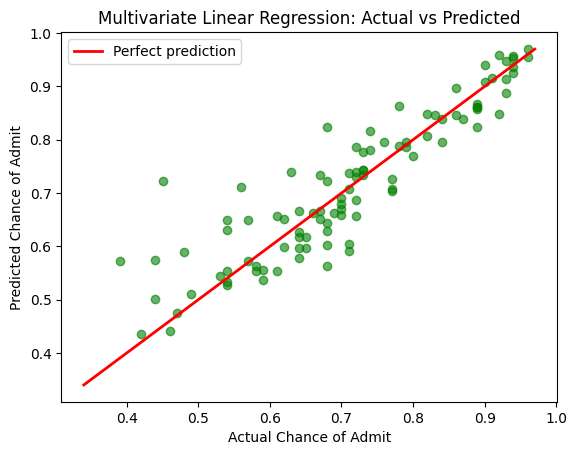

In [13]:
plt.scatter(y_test, y_pred, color='green', alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linewidth=2, label='Perfect prediction')
plt.xlabel('Actual Chance of Admit')
plt.ylabel('Predicted Chance of Admit')
plt.title('Multivariate Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()

In [14]:
simple_r2 = simple_lr.score(df[['GRE Score']], y)
multi_r2 = multi_lr.score(df, y)
print(f"Simple (GRE only) R²:     {simple_r2:.3f}")
print(f"Multivariate (all) R²:    {multi_r2:.3f}")

Simple (GRE only) R²:     0.657
Multivariate (all) R²:    0.821


R²: 0.9973922891706614


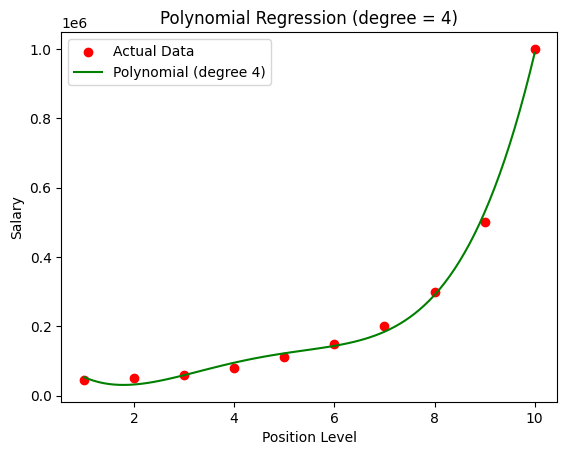

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures


df = pd.read_csv("/content/Position_Salaries.csv")
X = df[['Level']]
y = df['Salary']

poly = PolynomialFeatures(degree=4)
X_poly = poly.fit_transform(X)


poly_model = LinearRegression()
poly_model.fit(X_poly, y)


y_pred = poly_model.predict(X_poly)

X_grid = pd.DataFrame(np.arange(1, 10.1, 0.1), columns=['Level'])
plt.scatter(X, y, color='red', label='Actual Data')
plt.plot(X_grid, poly_model.predict(poly.transform(X_grid)), color='green', label='Polynomial (degree 4)')
plt.title('Polynomial Regression (degree = 4)')
plt.xlabel('Position Level')
plt.ylabel('Salary')
plt.legend()


print("R²:", poly_model.score(X_poly, y))
plt.show()



**Logistic Regression** (scratch)

In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


data = pd.read_csv('/content/Social_Network_Ads.csv')
labelencoder = LabelEncoder()
data['Gender'] = labelencoder.fit_transform(data['Gender'])  # Male=1, Female=0


X = data[['Gender', 'Age', 'EstimatedSalary']].values  # Select relevant columns
y = data['Purchased'].values


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


class LogisticRegression:
    def __init__(self, learning_rate=0.01, num_iterations=1000):
        self.lr = learning_rate
        self.iterations = num_iterations
        self.weights = None
        self.bias = None

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        num_samples, num_features = X.shape
        self.weights = np.zeros(num_features)
        self.bias = 0

        for i in range(self.iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self.sigmoid(linear_model)


            dw = (1 / num_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / num_samples) * np.sum(y_predicted - y)
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return [1 if i > 0.5 else 0 for i in self.sigmoid(linear_model)]


model = LogisticRegression(learning_rate=0.1, num_iterations=1000)
model.fit(X_train, y_train)


predictions = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, predictions))
print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))
print("Classification Report:\n", classification_report(y_test, predictions))

Accuracy: 0.8875
Confusion Matrix:
 [[50  2]
 [ 7 21]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92        52
           1       0.91      0.75      0.82        28

    accuracy                           0.89        80
   macro avg       0.90      0.86      0.87        80
weighted avg       0.89      0.89      0.88        80



**Logistic Regression (Sklearn)**

In [18]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = pd.read_csv("/content/Social_Network_Ads.csv")
le = LabelEncoder()
data['Gender'] = le.fit_transform(data['Gender'])

X = data[['Gender', 'Age', 'EstimatedSalary']].values
y = data['Purchased'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8875
Confusion Matrix:
 [[50  2]
 [ 7 21]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92        52
           1       0.91      0.75      0.82        28

    accuracy                           0.89        80
   macro avg       0.90      0.86      0.87        80
weighted avg       0.89      0.89      0.88        80

